# 01 Sensor EDA

Explores the raw water quality readings before cleaning, finds sensor faults, and
justifies every cleaning rule in `triton.cleaning`.

Input: `data/interim/sensor_readings.csv` from `python -m triton.parse`.
Figures are saved to `reports/figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from triton.cleaning import clean_readings
from triton.config import DATA, FAULT_PERIODS, INTERIM, SENSORS, STATIONS, VALID_RANGE
from triton.io import load

FIGURES = DATA.parent / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
FAULT = "#e34948"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": "#e6e6e3",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "lines.linewidth": 1,
    }
)
NAMES = {sid: f"{sid} {cfg['name']}" for sid, cfg in STATIONS.items()}
# One fixed colour per station across every figure.
COLOUR = dict(zip(STATIONS, COLOURS, strict=True))


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")


def series(sid, measure, start=None, end=None):
    mask = (readings["station_id"] == sid) & (readings["measure"] == measure)
    s = readings[mask].set_index("timestamp")["value"].sort_index()
    return s[start:end]

## 1. What each station records

In [2]:
readings = load("sensor_readings", INTERIM)
overview = readings.groupby(["station_id", "measure"]).agg(
    readings=("value", "size"),
    interval=("timestamp", lambda t: t.sort_values().diff().median()),
    first=("timestamp", "min"),
    last=("timestamp", "max"),
)
print(readings["quality"].value_counts(dropna=False).to_string())
overview

quality
Unchecked    1297605


readings        interval  \
station_id measure                                      
BREPON     ammonium             96617 0 days 00:15:00   
           conductivity         97766 0 days 00:15:00   
           dissolved-oxygen     97763 0 days 00:15:00   
           ph                   96423 0 days 00:15:00   
           temperature          97766 0 days 00:15:00   
           turbidity            33145 0 days 00:15:00   
E01336A    ammonium             24406 0 days 01:00:00   
           conductivity         24406 0 days 01:00:00   
           dissolved-oxygen     24406 0 days 01:00:00   
           ph                   24406 0 days 01:00:00   
           temperature          24406 0 days 01:00:00   
           turbidity            24406 0 days 01:00:00   
E26020A    ammonium             23682 0 days 01:00:00   
           conductivity         23682 0 days 01:00:00   
           dissolved-oxygen     23682 0 days 01:00:00   
           ph                   23682 0 days 01:00:00   
           temperature          23682 0 days 01:00:00   
           turbidity            23682 0 days 01:00:00   
HAMME2     ammonium             97477 0 days 00:15:00   
           conductivity         98030 0 days 00:15:00   
           dissolved-oxygen     98030 0 days 00:15:00   
           ph                   98030 0 days 00:15:00   
           temperature          98030 0 days 00:15:00   

                                                first  \
station_id measure                                      
BREPON     ammonium         2024-01-01 00:02:10+00:00   
           conductivity     2024-01-01 00:02:10+00:00   
           dissolved-oxygen 2024-01-01 00:02:10+00:00   
           ph               2024-01-01 00:02:10+00:00   
           temperature      2024-01-01 00:02:10+00:00   
           turbidity        2024-01-01 00:02:10+00:00   
E01336A    ammonium         2024-01-01 00:05:51+00:00   
           conductivity     2024-01-01 00:05:51+00:00   
           dissolved-oxygen 2024-01-01 00:05:51+00:00   
           ph               2024-01-01 00:05:51+00:00   
           temperature      2024-01-01 00:05:51+00:00   
           turbidity        2024-01-01 00:05:51+00:00   
E26020A    ammonium         2024-01-01 00:05:42+00:00   
           conductivity     2024-01-01 00:05:42+00:00   
           dissolved-oxygen 2024-01-01 00:05:42+00:00   
           ph               2024-01-01 00:05:42+00:00   
           temperature      2024-01-01 00:05:42+00:00   
           turbidity        2024-01-01 00:05:42+00:00   
HAMME2     ammonium         2024-01-01 00:00:35+00:00   
           conductivity     2024-01-01 00:00:35+00:00   
           dissolved-oxygen 2024-01-01 00:00:35+00:00   
           ph               2024-01-01 00:00:35+00:00   
           temperature      2024-01-01 00:00:35+00:00   

                                                 last  
station_id measure                                     
BREPON     ammonium         2026-10-17 18:15:26+00:00  
           conductivity     2026-10-17 18:15:26+00:00  
           dissolved-oxygen 2026-10-17 18:15:26+00:00  
           ph               2026-10-17 18:15:26+00:00  
           temperature      2026-10-17 18:15:26+00:00  
           turbidity        2024-12-13 11:47:10+00:00  
E01336A    ammonium         2026-10-17 18:05:16+00:00  
           conductivity     2026-10-17 18:05:16+00:00  
           dissolved-oxygen 2026-10-17 18:05:16+00:00  
           ph               2026-10-17 18:05:16+00:00  
           temperature      2026-10-17 18:05:16+00:00  
           turbidity        2026-10-17 18:05:16+00:00  
E26020A    ammonium         2026-10-17 18:01:23+00:00  
           conductivity     2026-10-17 18:01:23+00:00  
           dissolved-oxygen 2026-10-17 18:01:23+00:00  
           ph               2026-10-17 18:01:23+00:00  
           temperature      2026-10-17 18:01:23+00:00  
           turbidity        2026-10-17 18:01:23+00:00  
HAMME2     ammonium         2026-10-17 18:00:35+00:00  
 

- The two Lee stations log hourly; Hammersmith and Brentford every 15 minutes.
  Averaging to an hourly grid puts all four on the same footing.
- Every reading is flagged `Unchecked`: the EA has verified none of it, so the
  quality flag cannot be used to filter. Our own checks are the only cleaning.
- Hammersmith has no turbidity sensor, and Brentford turbidity stops in December 2024.

## 2. Coverage

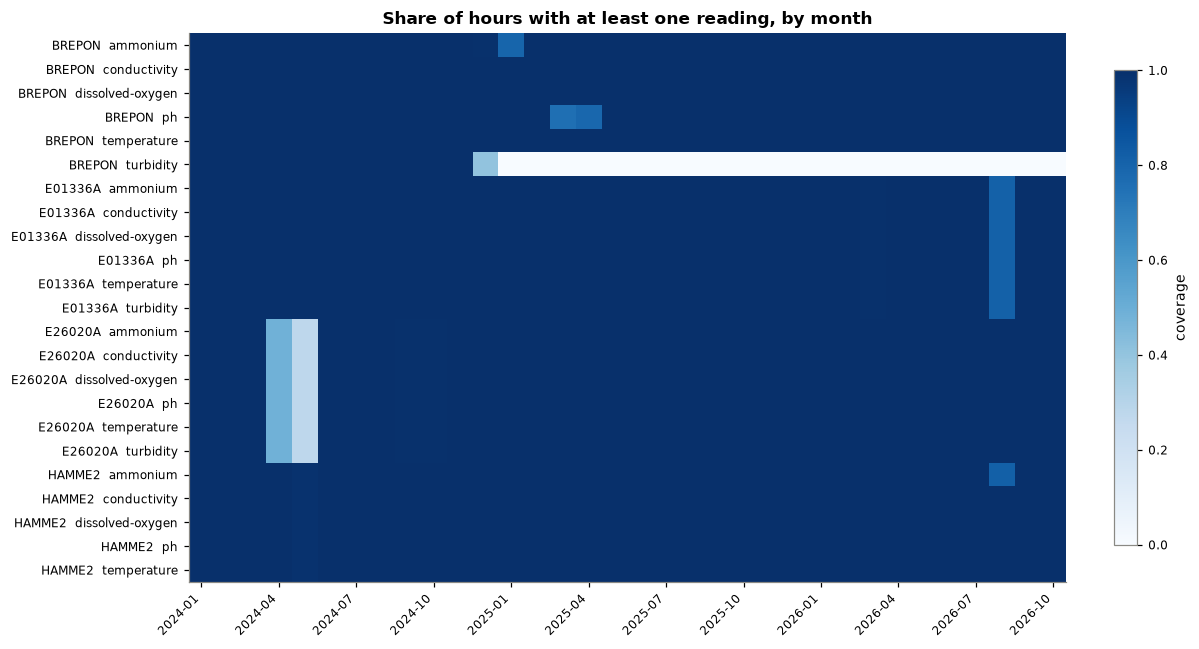

In [3]:
hours = readings.assign(hour=readings["timestamp"].dt.floor("1h")).drop_duplicates(
    ["station_id", "measure", "hour"]
)
monthly = (
    hours.groupby(["station_id", "measure", hours["hour"].dt.strftime("%Y-%m")])
    .size()
    .unstack()
)
expected = pd.Series(
    pd.date_range(
        readings["timestamp"].min().floor("1h"), readings["timestamp"].max(), freq="1h"
    )
    .strftime("%Y-%m")
    .value_counts()
)
coverage = (monthly / expected[monthly.columns]).fillna(0).clip(upper=1)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(coverage, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(coverage)), [f"{s}  {m}" for s, m in coverage.index])
ticks = range(0, coverage.shape[1], 3)
ax.set_xticks(ticks, coverage.columns[list(ticks)], rotation=45, ha="right")
ax.grid(False)
ax.set_title("Share of hours with at least one reading, by month")
fig.colorbar(im, ax=ax, fraction=0.025, label="coverage")
save(fig, "01_coverage")

Coverage is above 96% for every series except Brentford turbidity, which ends in
December 2024. The holes are a few outages: Lea Bridge in April and May 2024 (all
sensors, so the whole logger), Springfield Park in August 2026, and the Brentford
pH fault in early 2025. Gaps longer than 3 hours are left empty rather than invented.

## 3. Impossible values

In [4]:
def range_summary(group):
    lo, hi = VALID_RANGE[group.name[1]]
    bad = group["value"][~group["value"].between(lo, hi)]
    return pd.Series(
        {
            "valid_range": f"{lo} to {hi}",
            "min": group["value"].min(),
            "max": group["value"].max(),
            "out_of_range": len(bad),
            "out_of_range_pct": round(len(bad) / len(group) * 100, 2),
            "examples": sorted(bad.round(2).unique())[:4],
        }
    )


ranges = readings.groupby(["station_id", "measure"])[["value"]].apply(range_summary)
ranges[ranges["out_of_range"] > 0]

valid_range      min           max  out_of_range  \
station_id measure                                                             
BREPON     ph                   4 to 10   -5.030  1.807000e+01          3306   
           turbidity          0 to 1000 -196.600  1.558700e+03         33144   
E01336A    ammonium             0 to 50    0.216  9.999900e+04           140   
           conductivity      1 to 10000   -0.010  1.377070e+03            10   
           turbidity          0 to 1000   -0.300  9.704000e+02             1   
E26020A    ammonium             0 to 50    0.214  6.709000e+02             1   
           conductivity      1 to 10000    0.000  1.349450e+03            12   
           dissolved-oxygen     0 to 20    0.440  8.179000e+01             1   
           ph                   4 to 10    0.000  9.810000e+00             1   
           turbidity          0 to 1000    0.400  3.001340e+03             8   
HAMME2     ammonium             0 to 50    0.100  2.981160e+10             4   
           conductivity      1 to 10000   -0.140  2.349469e+04           123   
           ph                   4 to 10   -2.390  8.710000e+00             3   

                             out_of_range_pct  \
station_id measure                              
BREPON     ph                            3.43   
           turbidity                   100.00   
E01336A    ammonium                      0.57   
           conductivity                  0.04   
           turbidity                     0.00   
E26020A    ammonium                      0.00   
           conductivity                  0.05   
           dissolved-oxygen              0.00   
           ph                            0.00   
           turbidity                     0.03   
HAMME2     ammonium                      0.00   
           conductivity                  0.13   
           ph                            0.00   

                                                                     examples  
station_id measure                                                             
BREPON     ph                                     [-5.03, -5.01, -5.0, -4.99]  
           turbidity                         [-196.6, -196.5, -196.4, -196.3]  
E01336A    ammonium                               [54.5, 68.63, 69.01, 69.15]  
           conductivity                              [-0.01, 0.0, 0.14, 0.22]  
           turbidity                                                   [-0.3]  
E26020A    ammonium                                                   [670.9]  
           conductivity                               [0.0, 0.22, 0.23, 0.24]  
           dissolved-oxygen                                           [81.79]  
           ph                                                           [0.0]  
           turbidity                     [1018.17, 1078.82, 1111.01, 1232.82]  
HAMME2     ammonium          [1053.6, 91004640.0, 119041624.0, 29811599360.0]  
           conductivity                        [-0.14, -0.08, 0.22, 10041.67]  
           ph                                             [-2.39, 1.23, 2.78]

The valid ranges in `config.VALID_RANGE` are deliberately wide: they only reject
values that cannot occur in a river. What they catch:

- Error codes: ammonium of 99999 at Springfield Park, and values up to 3e10 at
  Hammersmith.
- Conductivity of 0 at the Lee stations: a sensor out of the water or disconnected.
- Brentford turbidity and pH, covered below.

## 4. Sensor faults

### 4.1 Brentford turbidity

count    33145.0
mean       -72.5
std         28.9
min       -196.6
25%        -77.3
50%        -59.2
75%        -54.2
max       1558.7


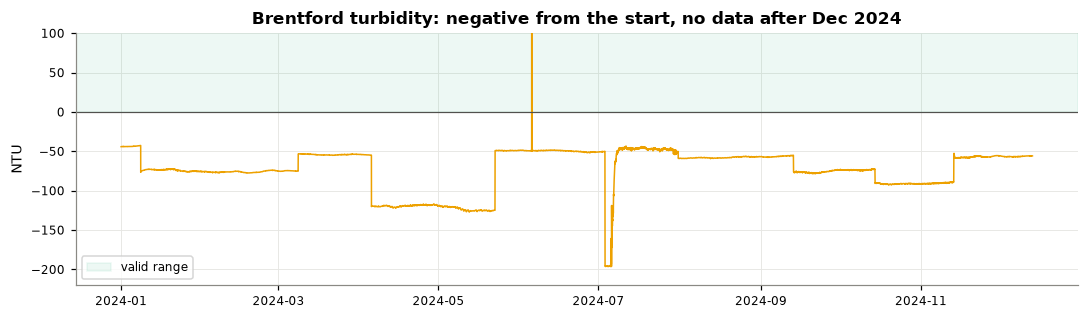

In [5]:
turb = series("BREPON", "turbidity")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(turb.index, turb, color=COLOUR["BREPON"])
ax.axhspan(*VALID_RANGE["turbidity"], color="#1baf7a", alpha=0.08, label="valid range")
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_ylim(-220, 100)
ax.set_ylabel("NTU")
ax.set_title("Brentford turbidity: negative from the start, no data after Dec 2024")
ax.legend(loc="lower left", fontsize=8)
save(fig, "01_brentford_turbidity")
print(turb.describe().round(1).to_string())

Turbidity cannot be negative, yet the median reading is about -59 NTU. This is a
calibration fault for the whole record, not a few bad values, and the sensor stops
on 13 December 2024. The range check removes all of it. **Turbidity is not usable
at Brentford.**

### 4.2 Brentford pH

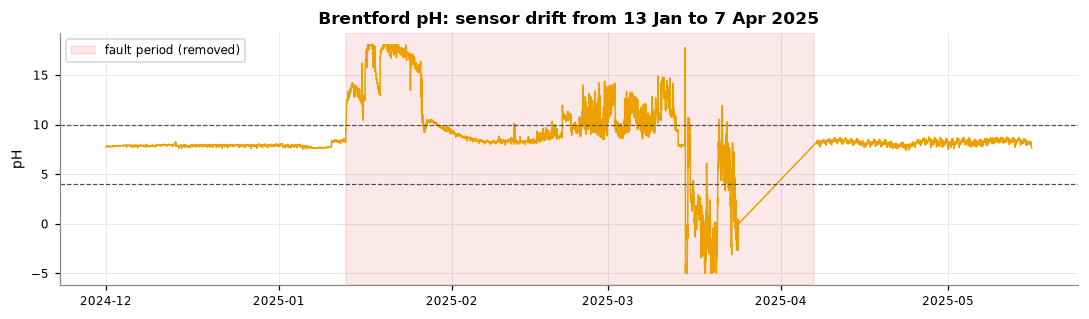

In [6]:
def shade_faults(ax, sid, measure):
    for start, end in FAULT_PERIODS.get((sid, measure), []):
        ax.axvspan(
            pd.Timestamp(start, tz="UTC"),
            pd.Timestamp(end, tz="UTC"),
            color=FAULT,
            alpha=0.12,
            label="fault period (removed)",
        )


ph = series("BREPON", "ph", "2024-12-01", "2025-05-15")
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(ph.index, ph, color=COLOUR["BREPON"])
shade_faults(ax, "BREPON", "ph")
for limit in VALID_RANGE["ph"]:
    ax.axhline(limit, color="#52514e", linewidth=0.8, linestyle="--")
ax.set_ylabel("pH")
ax.set_title("Brentford pH: sensor drift from 13 Jan to 7 Apr 2025")
ax.legend(loc="upper left", fontsize=8)
save(fig, "01_brentford_ph_fault")

pH jumps from about 8.3 to 13 on 13 January, sits near 18 for weeks, then falls
through normal values down to -5 before the sensor goes offline. River pH here
is normally 7.5 to 8.2. The dashed lines show the valid range: the range check
alone would keep the readings that pass through 8 to 10 on the way, which are
equally wrong. The whole window is removed through `config.FAULT_PERIODS`.

After the sensor returns in April it reads about 8.3, slightly higher than the 7.9
before the fault, which suggests a recalibration offset. It is kept because the
robust z-score compares each hour with the previous week, so a constant offset
does not create false anomalies.

### 4.3 Hammersmith conductivity: fault or tide?

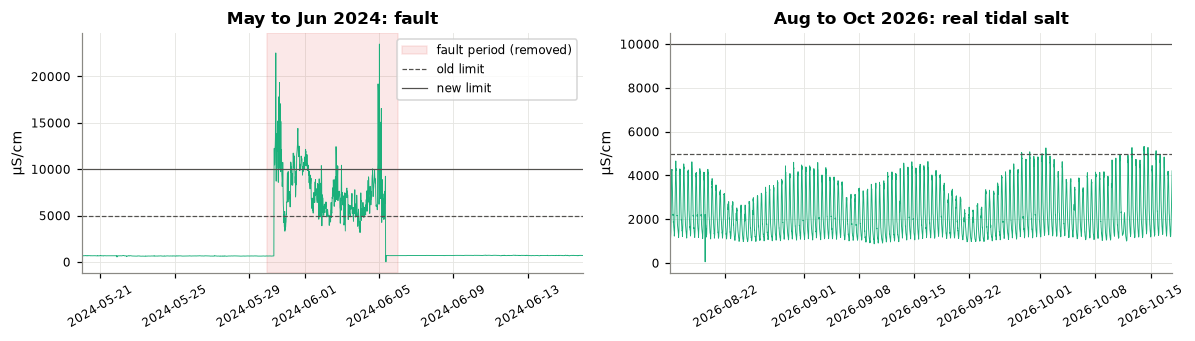

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (start, end, title) in zip(
    axes,
    [
        ("2024-05-20", "2024-06-15", "May to Jun 2024: fault"),
        ("2026-08-15", "2026-10-18", "Aug to Oct 2026: real tidal salt"),
    ],
    strict=True,
):
    cond = series("HAMME2", "conductivity", start, end)
    ax.plot(cond.index, cond, color=COLOUR["HAMME2"], linewidth=0.6)
    shade_faults(ax, "HAMME2", "conductivity")
    ax.set_xlim(cond.index.min(), cond.index.max())
    ax.axhline(5000, color="#52514e", linestyle="--", linewidth=0.8, label="old limit")
    ax.axhline(10000, color="#52514e", linewidth=0.8, label="new limit")
    ax.set_title(title)
    ax.set_ylabel("µS/cm")
    ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8, loc="upper right")
save(fig, "01_hammersmith_conductivity")

Hammersmith is on the tidal Thames, so conductivity rises at every high tide as
salty water pushes upstream.

- **Left:** in a normal week, readings jump from about 650 to 23,000 µS/cm and
  back. That is far beyond any tide this far upstream: a fault, removed as a fault
  period.
- **Right:** in the dry autumn of 2026 the tidal peaks climb steadily and a few
  pass 5,000 µS/cm. This is real salt water, so the old 5,000 limit was deleting
  valid data. The limit is now 10,000.

### 4.4 Frozen sensors

hours       [4.0, 6.0)  [6.0, 8.0)  [8.0, 10.0)  [10.0, 12.0)  [12.0, 24.0)  [24.0, 48.0)  [48.0, inf)
station_id                                                                                            
BREPON             153          34           15            14             6             0            0
E01336A            538          92           12             3             0             0            0
E26020A            359          52            8             0             0             0            0
HAMME2              92          19           12             2             0             5            0


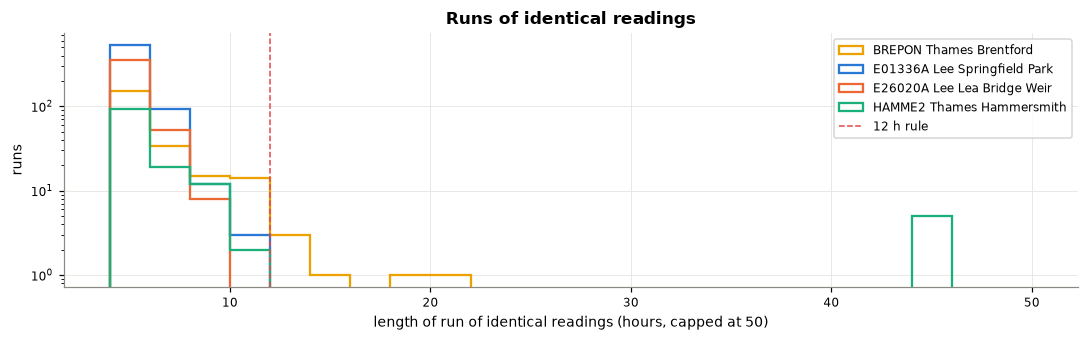

In [8]:
def frozen_runs(group):
    s = group.set_index("timestamp")["value"].sort_index()
    run = (~s.diff().eq(0)).cumsum()
    times = s.index.to_series()
    step = times.diff().median()
    span = times.groupby(run).agg(["min", "max", "size"])
    span["hours"] = (span["max"] - span["min"] + step) / pd.Timedelta("1h")
    return span[span["size"] > 1]


runs = readings.groupby(["station_id", "measure"])[["timestamp", "value"]].apply(
    frozen_runs
)
long_runs = runs[runs["hours"] >= 4]
bins = [4, 6, 8, 10, 12, 24, 48, np.inf]
print(
    pd.cut(long_runs["hours"], bins, right=False)
    .groupby(long_runs.index.get_level_values("station_id"), observed=False)
    .value_counts()
    .unstack()
    .to_string()
)

fig, ax = plt.subplots(figsize=(10, 3.2))
for sid, group in long_runs.groupby(level="station_id"):
    ax.hist(
        group["hours"].clip(upper=50),
        bins=np.arange(4, 52, 2),
        histtype="step",
        linewidth=1.5,
        color=COLOUR[sid],
        label=NAMES[sid],
    )
ax.axvline(12, color=FAULT, linestyle="--", linewidth=1, label="12 h rule")
ax.set_yscale("log")
ax.set_xlabel("length of run of identical readings (hours, capped at 50)")
ax.set_ylabel("runs")
ax.set_title("Runs of identical readings")
ax.legend(fontsize=8)
save(fig, "01_frozen_runs")

Identical consecutive readings are either a frozen logger or a calm river measured
at low precision (0.01 units, hourly at the Lee). Runs of 4 to 11 hours are common
at the Lee stations and look like the second case: they are spread through the
year and the readings either side differ by only 0.01. Genuine freezes are much
longer, up to 45 hours. A 12-hour rule removes the freezes and keeps the calm
periods; the earlier 6-hour rule deleted valid data, possibly during spills.

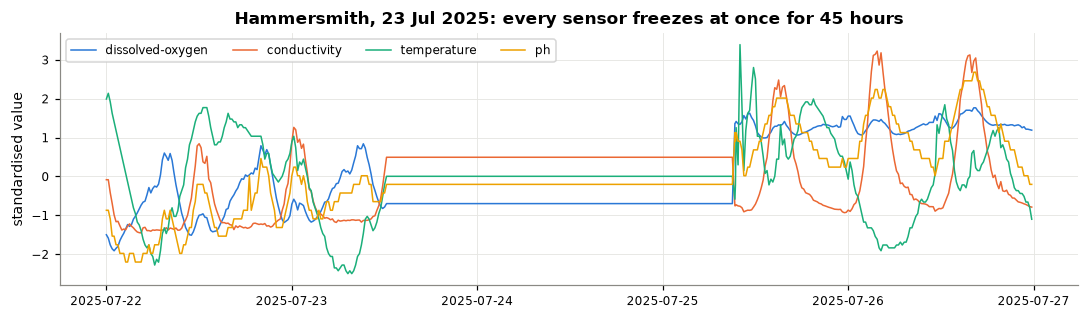

In [9]:
start, end = "2025-07-22", "2025-07-26"
fig, ax = plt.subplots(figsize=(10, 3))
for colour, measure in zip(
    COLOURS, ["dissolved-oxygen", "conductivity", "temperature", "ph"], strict=True
):
    s = series("HAMME2", measure, start, end)
    ax.plot(s.index, (s - s.mean()) / s.std(), color=colour, label=measure)
ax.set_ylabel("standardised value")
ax.set_title("Hammersmith, 23 Jul 2025: every sensor freezes at once for 45 hours")
ax.legend(fontsize=8, ncol=4, loc="upper left")
save(fig, "01_hammersmith_freeze")

Four independent sensors going flat at the same moment can only be the logger.
This 45-hour run is the clearest case the 12-hour rule is designed for.

## 5. Cleaning result

In [10]:
cleaned, quality = clean_readings(readings)
quality

,station_id,measure,hours,missing_raw_pct,fault_period_readings,out_of_range_readings,stuck_readings,filled_hours,missing_final_pct,longest_gap_h,large_spikes
0,BREPON,ammonium,24499,0.65,0,0,50,41,0.54,25,674
1,BREPON,conductivity,24499,0.00,0,0,0,1,0.00,1,702
2,BREPON,dissolved-oxygen,24499,0.00,0,0,0,1,0.00,1,43
3,BREPON,ph,24499,1.37,6759,0,0,1,8.27,2026,13
4,BREPON,temperature,24499,0.00,0,0,0,1,0.00,1,109
5,BREPON,turbidity,8340,0.01,0,33144,0,0,99.99,4582,0
6,E01336A,ammonium,24499,0.62,0,140,0,11,1.13,278,382
7,E01336A,conductivity,24499,0.62,0,10,0,13,0.58,142,1087
8,E01336A,dissolved-oxygen,24499,0.62,0,0,0,9,0.58,142,34
9,E01336A,ph,24499,0.62,0,0,0,9,0.58,142,5


In [11]:
before = hours.groupby(["station_id", "measure"]).size()
after = cleaned.groupby(["station_id", "measure"]).size()
grid_hours = quality.set_index(["station_id", "measure"])["hours"]
usable = pd.DataFrame(
    {
        "raw_pct": before / grid_hours * 100,
        "clean_pct": after.reindex(before.index, fill_value=0) / grid_hours * 100,
    }
).round(1)
usable

raw_pct  clean_pct
station_id measure                             
BREPON     ammonium             99.3       99.5
           conductivity        100.0      100.0
           dissolved-oxygen    100.0      100.0
           ph                   98.6       91.7
           temperature         100.0      100.0
           turbidity           100.0        0.0
E01336A    ammonium             99.4       98.9
           conductivity         99.4       99.4
           dissolved-oxygen     99.4       99.4
           ph                   99.4       99.4
           temperature          99.4       99.4
           turbidity            99.4       99.4
E26020A    ammonium             96.2       96.3
           conductivity         96.2       96.3
           dissolved-oxygen     96.2       96.3
           ph                   96.2       96.3
           temperature          96.2       96.3
           turbidity            96.2       96.3
HAMME2     ammonium             99.4       99.2
           conductivity        100.0       99.1
           dissolved-oxygen    100.0       99.8
           ph                  100.0       99.8
           temperature         100.0       99.8

`raw_pct` is the share of hours with any reading, `clean_pct` the share left after
cleaning (including filled gaps of 3 hours or less). Apart from Brentford
turbidity and the Brentford pH fault, cleaning removes very little: the data is
mostly sound, and the faults are concentrated in a few clear episodes.

## 6. Natural cycles

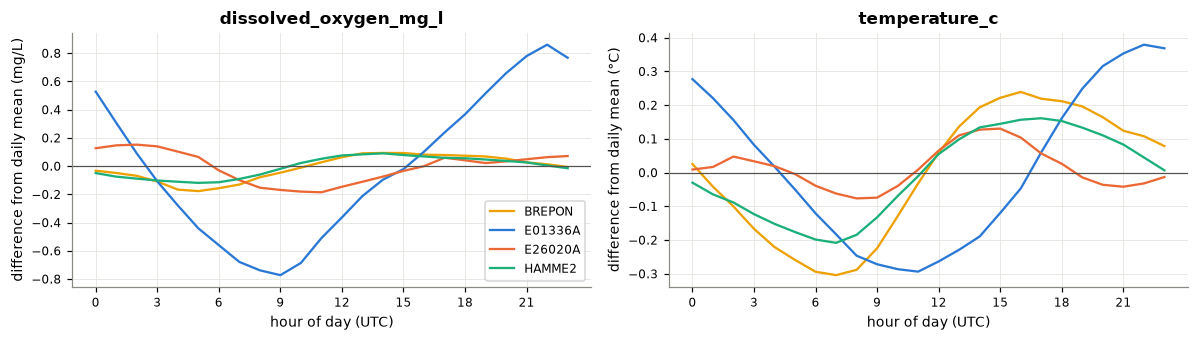

In [12]:
wide = (
    cleaned.pivot_table(
        index=["station_id", "timestamp"], columns="measure", values="value"
    )
    .rename(columns=SENSORS)
    .reset_index()
)
wide["hour"] = wide["timestamp"].dt.hour
wide["day"] = wide["timestamp"].dt.floor("1D")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, column, unit in zip(
    axes,
    ["dissolved_oxygen_mg_l", "temperature_c"],
    ["mg/L", "°C"],
    strict=True,
):
    daily_mean = wide.groupby(["station_id", "day"])[column].transform("mean")
    profile = (
        (wide[column] - daily_mean)
        .groupby([wide["station_id"], wide["hour"]])
        .median()
        .unstack(0)
    )
    for sid in profile.columns:
        ax.plot(
            profile.index, profile[sid], color=COLOUR[sid], linewidth=1.5, label=sid
        )
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("hour of day (UTC)")
    ax.set_ylabel(f"difference from daily mean ({unit})")
    ax.set_title(column)
axes[0].legend(fontsize=8)
save(fig, "01_daily_cycle")

Every station has a daily cycle, but the shapes differ:

- At the Thames stations, oxygen is lowest around dawn and highest in the afternoon,
  the expected pattern from plants and algae producing oxygen in daylight.
  Temperature peaks mid afternoon.
- Springfield Park has the largest swings, with its oxygen low around 09:00 and
  peak around 22:00. Lea Bridge, just downstream, has a much weaker cycle.

Either way, the label must not treat a normal night time dip as pollution. The
robust z-score compares each hour with the previous 7 days, which absorbs the cycle.

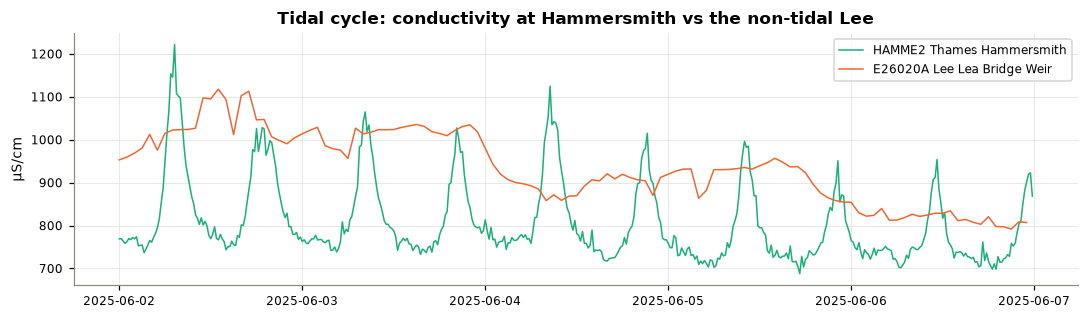

In [13]:
start, end = "2025-06-02", "2025-06-06"
fig, ax = plt.subplots(figsize=(10, 3))
for sid in ["HAMME2", "E26020A"]:
    s = series(sid, "conductivity", start, end)
    ax.plot(s.index, s, color=COLOUR[sid], label=NAMES[sid])
ax.set_ylabel("µS/cm")
ax.set_title("Tidal cycle: conductivity at Hammersmith vs the non-tidal Lee")
ax.legend(fontsize=8)
save(fig, "01_tidal_cycle")

### 6.1 Timing check between stations

In [14]:
def daily_part(sid, measure):
    s = cleaned[(cleaned["station_id"] == sid) & (cleaned["measure"] == measure)]
    s = s.set_index("timestamp")["value"].asfreq("1h")
    return s - s.rolling("24h", center=True).mean()


rows = []
for measure in ["temperature", "dissolved-oxygen"]:
    upstream = daily_part("E01336A", measure)
    downstream = daily_part("E26020A", measure)
    corr = {k: upstream.corr(downstream.shift(-k)) for k in range(-12, 13)}
    best = max(corr, key=corr.get)
    rows.append(
        {
            "measure": measure,
            "lea_bridge_trails_by_h": best,
            "corr_at_best": round(corr[best], 2),
            "corr_at_0": round(corr[0], 2),
        }
    )
pd.DataFrame(rows)

,measure,lea_bridge_trails_by_h,corr_at_best,corr_at_0
0,temperature,4,0.43,0.07
1,dissolved-oxygen,5,0.36,0.08


Springfield Park and Lea Bridge are 1.3 km apart on the same river. Their daily
cycles match best when Lea Bridge is shifted 4 to 5 hours later, for both
temperature and oxygen. At the slow flow of the lower Lee (around 0.1 m/s),
1.3 km takes roughly 3.5 hours, so this is the same water arriving later. The
timestamps are consistent, and pollution should also reach Lea Bridge a few hours
after Springfield Park, which notebook 02 checks against spills.

A daily cycle repeats every 24 hours, so this check can only show the order and
rough size of the delay, not an exact travel time.

Conductivity at Hammersmith rises and falls twice a day with the tide; the Lee
is not tidal and changes slowly over days. Tidal swings are large and regular, so models for
the Thames stations need tide-aware features (for example hour of the tidal
cycle, or change from the same point in the previous cycle) or they will confuse
tides with pollution. This is also why the Thames stations have lower anomaly lift
than the Lee.

## 7. How the sensors relate

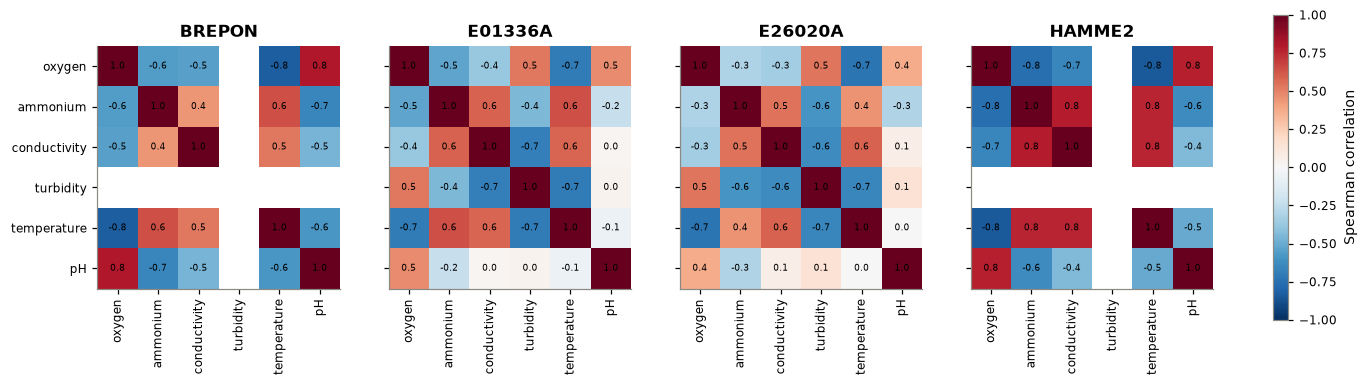

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
columns = list(SENSORS.values())
SHORT = ["oxygen", "ammonium", "conductivity", "turbidity", "temperature", "pH"]
for ax, (sid, group) in zip(axes, wide.groupby("station_id"), strict=True):
    corr = group[columns].corr(method="spearman")
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(columns)), SHORT, rotation=90)
    ax.set_yticks(range(len(columns)), SHORT)
    ax.set_title(sid)
    ax.grid(False)
    for i in range(len(columns)):
        for j in range(len(columns)):
            if not np.isnan(corr.iloc[i, j]):
                value = f"{corr.iloc[i, j]:.1f}"
                ax.text(j, i, value, ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes, fraction=0.015, label="Spearman correlation")
fig.savefig(FIGURES / "01_correlations.png", bbox_inches="tight")

Spearman correlation is used because the readings are skewed and spiky.

- Oxygen and temperature are strongly negative everywhere (-0.7 to -0.8): warm
  water holds less oxygen.
- At the Thames stations, ammonium rises with temperature and conductivity (0.6 to
  0.8). All three follow the season: summer brings warm water, low flow and less
  dilution.
- Most of these correlations are seasonal, not caused by pollution events. Raw
  levels therefore say little on their own: a model should use changes and
  deviations from the recent baseline, which is what the label already does.
- Turbidity is empty at Brentford and Hammersmith (broken or no sensor).

## Findings

1. **Mostly sound data.** After cleaning, every series keeps 91% or more of its
   hours, except Brentford turbidity.
2. **Faults come in a few clear episodes**, each now handled by a rule:
   - Brentford turbidity, always negative: removed by the range check, not usable.
   - Brentford pH, 13 Jan to 7 Apr 2025: fault period.
   - Hammersmith conductivity, 30 May to 6 Jun 2024: fault period.
   - Hammersmith logger freeze on 23 Jul 2025, and Brentford ammonium plateaus:
     the 12-hour frozen rule.
   - Error codes such as 99999: the range check.
3. **Two rules were changed because of this EDA.** The frozen rule went from 6 to
   12 hours, because runs under 12 hours are normal at 0.01 precision. The
   conductivity limit went from 5,000 to 10,000 µS/cm, because tidal salt water
   at Hammersmith is real.
4. **The quality flag is useless**: everything is `Unchecked`.
5. **Strong natural cycles**, daily (oxygen, temperature) and tidal (conductivity
   on the Thames). Models need baseline-relative features and, for the Thames,
   tide-aware ones.
6. **Travel time on the Lee:** Lea Bridge's daily cycle trails Springfield Park by
   4 to 5 hours, the same water arriving later. Upstream readings may therefore
   help warn the downstream station.